# NanoServe — Week 2: FlashAttention forward in Triton

**Goal for the week (v0.2):** write an attention kernel that never stores the N×N score matrix, add the causal mask GPT-style models need, and show the memory and speed win against naive attention.

**Before you start:** *Runtime → Change runtime type → T4 GPU*.

| Day | Section | Read / watch first |
|---|---|---|
| 1 | Naive attention and its N² memory | FlashAttention paper, sections 1–2 |
| 2 | Tiled attention in plain PyTorch | FlashAttention paper, section 3.1 + Algorithm 1 |
| 3 | Triton kernel, no mask | Triton tutorial 03 (matmul) — just how `tl.dot` and 2-D pointer blocks work |
| 4 | Causal mask + skipping blocks | Re-read Algorithm 1 with the mask in mind |
| 5 | Benchmarks: memory and speed | — |
| 6 | Tuning block sizes with autotune | Triton tutorial 06 (fused attention) — skim |
| 7 | README v0.2 | Template at the bottom |

Same rule as week 1: **correct first, fast second.** If you get stuck, `flash_solutions.py` has a working answer key — try for 30 minutes before opening it.

---
## Day 1 — Naive attention and why it doesn't scale

Read first: [FlashAttention (Dao et al., 2022)](https://arxiv.org/abs/2205.14135), sections 1–2.

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right)V$$

Shapes: `q, k, v` are `(batch, heads, N, d)`. The score matrix `QKᵀ` is `(batch, heads, N, N)` — that's the problem.

In [1]:
!nvidia-smi
import math, torch, triton, triton.language as tl
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), "No GPU. Runtime -> Change runtime type -> T4 GPU"
DEVICE = torch.device("cuda")
DTYPE = torch.float16          # T4 has fast fp16 tensor cores; it does not support bf16 well
GPU_NAME = torch.cuda.get_device_name(0)
PEAK_TFLOPS = {"Tesla T4": 65, "NVIDIA L4": 121, "NVIDIA A100-SXM4-40GB": 312}.get(GPU_NAME)  # fp16 tensor core, dense
print(GPU_NAME, "| fp16 peak:", PEAK_TFLOPS, "TFLOPS | torch", torch.__version__, "| triton", triton.__version__)

Tue Oct 20 03:53:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
def naive_attention(q, k, v, causal=False):
    d = q.shape[-1]
    s = (q @ k.transpose(-1, -2)) / math.sqrt(d)            # (B, H, N, N) written to GPU memory
    if causal:
        N = q.shape[-2]
        mask = torch.ones(N, N, device=q.device, dtype=torch.bool).triu(1)
        s = s.masked_fill(mask, float("-inf"))
    p = torch.softmax(s.float(), dim=-1).to(q.dtype)          # another (B, H, N, N)
    return p @ v


def make_qkv(B=2, H=8, N=1024, D=64):
    return [torch.randn(B, H, N, D, device=DEVICE, dtype=DTYPE) for _ in range(3)]


q, k, v = make_qkv(N=512)
torch.testing.assert_close(naive_attention(q, k, v), F.scaled_dot_product_attention(q, k, v), rtol=2e-3, atol=2e-3)
torch.testing.assert_close(naive_attention(q, k, v, causal=True),
                           F.scaled_dot_product_attention(q, k, v, is_causal=True), rtol=2e-3, atol=2e-3)
print("naive attention: correct")

naive attention: correct


In [3]:
def peak_memory_mb(fn, *args):
    # Extra GPU memory a call needs beyond its inputs, in MB. Returns None if it runs out of memory.
    torch.cuda.synchronize(); torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    before = torch.cuda.memory_allocated()
    try:
        out = fn(*args); torch.cuda.synchronize()
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache(); return None
    peak = torch.cuda.max_memory_allocated() - before
    del out; torch.cuda.empty_cache()
    return peak / 2**20


for N in [1024, 2048, 4096, 8192, 16384]:
    q, k, v = make_qkv(N=N)
    mb = peak_memory_mb(naive_attention, q, k, v)
    print(f"N={N:>6}: naive attention needs {'OUT OF MEMORY' if mb is None else f'{mb:,.0f} MB'}")
    del q, k, v

N=  1024: naive attention needs 160 MB
N=  2048: naive attention needs 640 MB
N=  4096: naive attention needs 2,560 MB
N=  8192: naive attention needs 10,240 MB
N= 16384: naive attention needs OUT OF MEMORY


**What to notice:** each doubling of N multiplies memory by ~4. Write down where the T4 runs out — by the end of the week your kernel will run past that point.

---
## Day 2 — Tiled attention in plain PyTorch

Read first: FlashAttention paper, **section 3.1 and Algorithm 1**.

This is week 1's online softmax with one addition: alongside the running max `m` and running sum `l`, we keep a running **output** `acc`. When a new block raises the max, `acc` is rescaled by the same factor as `l`:

$$m_{new} = \max(m,\ \text{rowmax}(S)) \qquad \alpha = e^{\,m - m_{new}} \qquad P = e^{\,S - m_{new}}$$
$$l \leftarrow \alpha\, l + \text{rowsum}(P) \qquad acc \leftarrow \alpha\, acc + P V \qquad \text{output} = acc / l$$

Write it in PyTorch first — debugging here is far easier than inside a kernel. Each `(start_m)` iteration below becomes **one Triton program** tomorrow.

In [4]:
def flash_attention_reference(q, k, v, causal=False, BLOCK_M=64, BLOCK_N=64):
    B, H, N, D = q.shape
    scale = 1.0 / math.sqrt(D)
    out = torch.empty_like(q)
    for start_m in range(0, N, BLOCK_M):                     # one block of query rows
        q_blk = q[:, :, start_m:start_m + BLOCK_M].float()
        M_blk = q_blk.shape[2]
        m_i = torch.full((B, H, M_blk), float("-inf"), device=q.device)
        l_i = torch.zeros((B, H, M_blk), device=q.device)
        acc = torch.zeros((B, H, M_blk, D), device=q.device)

        for start_n in range(0, N, BLOCK_N):                 # walk over key/value blocks
            k_blk = k[:, :, start_n:start_n + BLOCK_N].float()
            v_blk = v[:, :, start_n:start_n + BLOCK_N].float()
            s = (q_blk @ k_blk.transpose(-1, -2)) * scale    # (B, H, BLOCK_M, BLOCK_N) — small!

            # TODO 1: m_new = elementwise max of m_i and the row max of s  (s.amax(-1))
            m_new = torch.maximum(m_i,s.amax(-1))
            # TODO 2: alpha = torch.exp(m_i - m_new)
            alpha  = torch.exp(m_i- m_new )
            # TODO 3: p = torch.exp(s - m_new[..., None])
            p = torch.exp(s - m_new[..., None])
            l_i = l_i * alpha + p.sum(-1)
            acc = acc * alpha[..., None] + p @ v_blk
            m_i = m_new
            pass

        out[:, :, start_m:start_m + BLOCK_M] = (acc / l_i[..., None]).to(q.dtype)
    return out

In [5]:
# Small, awkward sizes: N not a multiple of the block size on purpose
for N in [1, 5, 64, 100, 257]:
    q, k, v = make_qkv(B=2, H=3, N=N, D=32)
    torch.testing.assert_close(flash_attention_reference(q, k, v),
                               F.scaled_dot_product_attention(q, k, v), rtol=2e-3, atol=2e-3)
print("tiled reference: correct")

tiled reference: correct


**Check your understanding before moving on:** what is the largest tensor the tiled version ever creates? Compare it with naive attention's `(B, H, N, N)`.

---
## Day 3 — The Triton kernel (no mask yet)

Read first: [Triton tutorial 03 — Matrix Multiplication](https://triton-lang.org/main/getting-started/tutorials/03-matrix-multiplication.html), only to see how 2-D blocks of pointers and `tl.dot` work.

**Grid:** one program per (block of query rows, batch × head). Each program loads its `Q` block once, then loops over `K`/`V` blocks — the exact loop you wrote yesterday.

New Triton ideas:
- **2-D pointer blocks:** `base + rows[:, None] * row_stride + cols[None, :]` gives a `(rows, cols)` grid of addresses.
- **`tl.dot(a, b)`** multiplies two blocks on the tensor cores. Both sides must have dimensions ≥ 16.
- Loading `K` already **transposed** (shape `(D, BLOCK_N)`) by swapping the roles of rows and columns in the pointer maths, so `tl.dot(q, k)` gives `QKᵀ` directly.
- Keep `m_i`, `l_i`, `acc` in **fp32** even though inputs are fp16 — the rescaling is sensitive to rounding.

In [6]:
@triton.jit
def flash_attn_fwd_kernel(
    Q, K, V, Out,
    stride_qb, stride_qh, stride_qn,
    stride_kb, stride_kh, stride_kn,
    stride_vb, stride_vh, stride_vn,
    stride_ob, stride_oh, stride_on,
    H, N, scale,
    D: tl.constexpr, BLOCK_M: tl.constexpr, BLOCK_N: tl.constexpr, CAUSAL: tl.constexpr,
):
    start_m = tl.program_id(0)               # which block of query rows
    bh = tl.program_id(1)                    # which (batch, head)
    b = bh // H
    h = bh % H

    offs_m = start_m * BLOCK_M + tl.arange(0, BLOCK_M)   # query row indices
    offs_n = tl.arange(0, BLOCK_N)                        # key indices within a block
    offs_d = tl.arange(0, D)

    # Load this program's Q block once: shape (BLOCK_M, D)
    q_ptrs = Q + b * stride_qb + h * stride_qh + offs_m[:, None] * stride_qn + offs_d[None, :]
    q = tl.load(q_ptrs, mask=offs_m[:, None] < N, other=0.0)

    m_i = tl.full([BLOCK_M], float("-inf"), dtype=tl.float32)
    l_i = tl.zeros([BLOCK_M], dtype=tl.float32)
    acc = tl.zeros([BLOCK_M, D], dtype=tl.float32)

    # Day 4: change this when CAUSAL to skip unnecessary blocks
    end_n = tl.minimum((start_m + 1) * BLOCK_M, N) if CAUSAL else N

    for start_n in range(0, end_n, BLOCK_N):
        cols = start_n + offs_n

        # K block loaded transposed: shape (D, BLOCK_N)
        k_ptrs = K + b * stride_kb + h * stride_kh + cols[None, :] * stride_kn + offs_d[:, None]
        k = tl.load(k_ptrs, mask=cols[None, :] < N, other=0.0)

        # TODO 1: s = tl.dot(q, k) * scale                      -> (BLOCK_M, BLOCK_N)
        s = tl.dot(q, k) * scale

        # TODO 2: padding columns (cols >= N) must not count
        if CAUSAL:
            mask = (cols[None, :] < N) & (cols[None, :] <= offs_m[:, None])
            s = tl.where(mask, s, float("-inf"))
        else:
            s = tl.where(cols[None, :] < N, s, float("-inf"))

        # TODO 3: m_new = tl.maximum(m_i, tl.max(s, axis=1))
        m_new = tl.maximum(m_i, tl.max(s, axis=1))
        # TODO 4: alpha = tl.exp(m_i - m_new);  p = tl.exp(s - m_new[:, None])
        alpha = tl.exp(m_i - m_new)
        p = tl.exp(s - m_new[:, None])
        # TODO 5: l_i = l_i * alpha + tl.sum(p, axis=1)
        l_i = l_i * alpha + tl.sum(p, axis=1)

        # V block: shape (BLOCK_N, D)
        v_ptrs = V + b * stride_vb + h * stride_vh + cols[:, None] * stride_vn + offs_d[None, :]
        v = tl.load(v_ptrs, mask=cols[:, None] < N, other=0.0)

        # TODO 6: acc = acc * alpha[:, None] + tl.dot(p.to(v.dtype), v)
        #         (p is fp32; cast to fp16 so tl.dot runs on the tensor cores)
        acc = acc * alpha[:, None] + tl.dot(p.to(v.dtype), v)
        # TODO 7: m_i = m_new
        m_i = m_new

    acc = acc / l_i[:, None]
    o_ptrs = Out + b * stride_ob + h * stride_oh + offs_m[:, None] * stride_on + offs_d[None, :]
    tl.store(o_ptrs, acc.to(Out.dtype.element_ty), mask=offs_m[:, None] < N)


def triton_flash_attention(q, k, v, causal=False, BLOCK_M=64, BLOCK_N=64, num_warps=4, num_stages=2):
    B, H, N, D = q.shape
    assert D in (16, 32, 64, 128), "head dim must be a power of two >= 16"
    q, k, v = q.contiguous(), k.contiguous(), v.contiguous()
    out = torch.empty_like(q)
    grid = (triton.cdiv(N, BLOCK_M), B * H)
    flash_attn_fwd_kernel[grid](
        q, k, v, out,
        q.stride(0), q.stride(1), q.stride(2),
        k.stride(0), k.stride(1), k.stride(2),
        v.stride(0), v.stride(1), v.stride(2),
        out.stride(0), out.stride(1), out.stride(2),
        H, N, 1.0 / math.sqrt(D),
        D=D, BLOCK_M=BLOCK_M, BLOCK_N=BLOCK_N, CAUSAL=causal,
        num_warps=num_warps, num_stages=num_stages,
    )
    return out

In [7]:
for N, D in [(1, 16), (5, 32), (64, 64), (100, 32), (1000, 64), (4096, 128)]:
    q, k, v = make_qkv(B=2, H=4, N=N, D=D)
    torch.testing.assert_close(triton_flash_attention(q, k, v),
                               F.scaled_dot_product_attention(q, k, v), rtol=2e-3, atol=2e-3)
print("triton flash attention (no mask): correct")

triton flash attention (no mask): correct


**Debugging tips:**
- Output is all `nan` → a row of `s` was entirely `-inf` while `m_i` was also `-inf`, so `exp(-inf - (-inf))` = `nan`. Check your masks.
- Wrong only when N isn't a multiple of 64 → a missing `mask=` or a wrong `other=`.
- Compile error about `tl.dot` shapes → every dimension passed to `tl.dot` must be ≥ 16.
- To step through a kernel on CPU with prints, set `os.environ["TRITON_INTERPRET"] = "1"` **before** importing triton (restart the runtime), and use CPU tensors.

---
## Day 4 — Causal mask, and skipping work

In GPT-style models, token *i* may only attend to tokens ≤ *i*. Two changes:

1. **Mask inside a block:** a score is valid only if `col <= row`. Add `& (cols[None, :] <= offs_m[:, None])` to the condition in TODO 2 when `CAUSAL`.
2. **Skip whole blocks:** key blocks that start after this program's last query row are entirely masked. Don't even load them — set
   `end_n = tl.minimum((start_m + 1) * BLOCK_M, N)` when `CAUSAL`.

Change 2 is where the speed comes from: it skips roughly half the work. Use `if CAUSAL:` — since `CAUSAL` is a `tl.constexpr`, Triton compiles two separate kernels and the branch costs nothing.

**Why no `nan` here?** Every program's first key block contains column 0, which is ≤ every row, so each row always has at least one valid score in its first block.

In [8]:
for N, D in [(1, 16), (5, 32), (64, 64), (100, 32), (1000, 64), (4096, 128)]:
    q, k, v = make_qkv(B=2, H=4, N=N, D=D)
    torch.testing.assert_close(triton_flash_attention(q, k, v, causal=True),
                               F.scaled_dot_product_attention(q, k, v, is_causal=True), rtol=2e-3, atol=2e-3)
print("triton flash attention (causal): correct")

triton flash attention (causal): correct


---
## Day 5 — Benchmarks: memory and speed

For attention we report **TFLOPS** rather than GB/s, because with tiling it becomes compute-heavy. The two matmuls cost `4 · B · H · N² · D` FLOPs; causal does half of that.

`F.scaled_dot_product_attention` is the strong baseline. On a T4 PyTorch can't use its own FlashAttention kernels (they need newer GPUs), so it picks a "memory-efficient" kernel instead. Losing to it is fine — measure the gap and explain it.

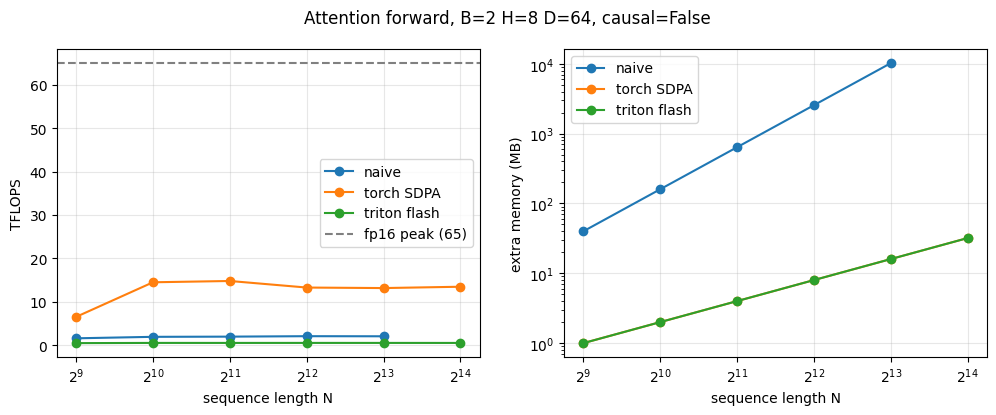

TFLOPS                               MB                        
impl   naive torch SDPA triton flash    naive torch SDPA triton flash
N                                                                    
512      1.6        6.5          0.5     40.0        1.0          1.0
1024     1.9       14.5          0.5    160.0        2.0          2.0
2048     2.0       14.8          0.5    640.0        4.0          4.0
4096     2.1       13.3          0.5   2560.0        8.0          8.0
8192     2.1       13.2          0.5  10240.0       16.0         16.0
16384    NaN       13.5          0.5      NaN       32.0         32.0

In [9]:
def attn_flops(B, H, N, D, causal):
    f = 4 * B * H * N * N * D
    return f / 2 if causal else f


def bench_attention(causal: bool, B=2, H=8, D=64, sizes=(512, 1024, 2048, 4096, 8192, 16384)):
    impls = {
        "naive": lambda q, k, v: naive_attention(q, k, v, causal),
        "torch SDPA": lambda q, k, v: F.scaled_dot_product_attention(q, k, v, is_causal=causal),
        "triton flash": lambda q, k, v: triton_flash_attention(q, k, v, causal),
    }
    rows = []
    for N in sizes:
        q, k, v = make_qkv(B, H, N, D)
        for name, fn in impls.items():
            mem = peak_memory_mb(fn, q, k, v)
            if mem is None:
                rows.append({"N": N, "impl": name, "ms": None, "TFLOPS": None, "MB": None})
                continue
            ms = triton.testing.do_bench(lambda: fn(q, k, v))
            rows.append({"N": N, "impl": name, "ms": ms,
                         "TFLOPS": attn_flops(B, H, N, D, causal) / (ms * 1e-3) / 1e12, "MB": mem})
        del q, k, v; torch.cuda.empty_cache()
    df = pd.DataFrame(rows)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, g in df.groupby("impl"):
        axes[0].plot(g["N"], g["TFLOPS"], marker="o", label=name)
        axes[1].plot(g["N"], g["MB"], marker="o", label=name)
    if PEAK_TFLOPS:
        axes[0].axhline(PEAK_TFLOPS, ls="--", color="gray", label=f"fp16 peak ({PEAK_TFLOPS})")
    axes[0].set_ylabel("TFLOPS"); axes[1].set_ylabel("extra memory (MB)"); axes[1].set_yscale("log")
    for ax in axes:
        ax.set_xscale("log", base=2); ax.set_xlabel("sequence length N"); ax.grid(alpha=0.3); ax.legend()
    fig.suptitle(f"Attention forward, B={B} H={H} D={D}, causal={causal}")
    plt.show()
    return df.pivot(index="N", columns="impl", values=["TFLOPS", "MB"]).round(1)


bench_attention(causal=False)

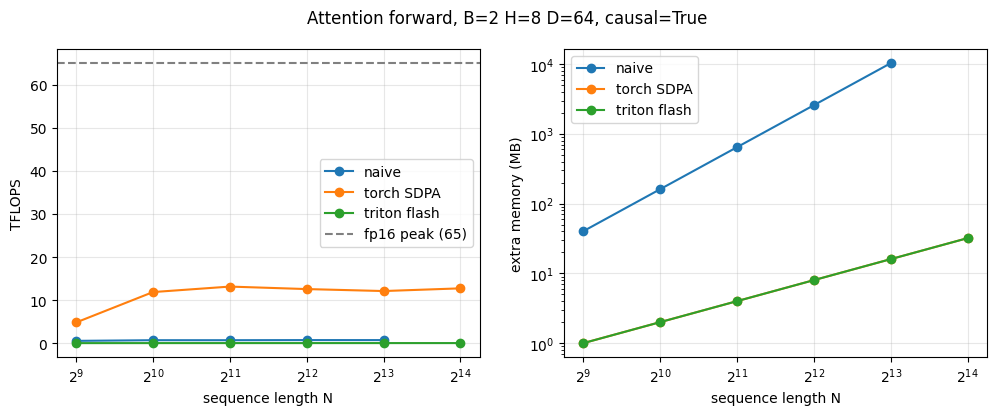

TFLOPS                               MB                        
impl   naive torch SDPA triton flash    naive torch SDPA triton flash
N                                                                    
512      0.6        4.9          0.1     40.2        1.0          1.0
1024     0.8       11.9          0.1    161.0        2.0          2.0
2048     0.8       13.2          0.1    644.0        4.0          4.0
4096     0.8       12.6          0.1   2576.0        8.0          8.0
8192     0.8       12.2          0.1  10304.0       16.0         16.0
16384    NaN       12.8          0.1      NaN       32.0         32.0

In [10]:
bench_attention(causal=True)

** **bold text**Questions for the README:**
- Where does naive attention run out of memory? How far past that point does your kernel go?
- How does your kernel's memory grow with N, compared with naive's?
- Did causal masking get close to the expected 2× speedup? If not, why might it fall short? (Hint: look at the diagonal blocks and at how many programs have little work to do.)
- What fraction of the T4's fp16 peak do you reach? How far are you from SDPA?

---
## Day 6 — Tuning with autotune

Block sizes and `num_warps` change speed a lot, and the best choice depends on the GPU and on D. Triton's `@triton.autotune` tries a list of configurations the first time a shape is seen and keeps the fastest.

Below we sweep configurations by hand so you can **see** the effect — a table like this is great README material. Then optionally wrap the kernel in `@triton.autotune` (see tutorial 06 for the syntax).

On a T4, `num_stages` above 2 usually doesn't help: the asynchronous copy hardware that makes pipelining pay off arrived with the next GPU generation.

In [11]:
B, H, N, D = 2, 8, 4096, 64
q, k, v = make_qkv(B, H, N, D)
rows = []
for BLOCK_M in [32, 64, 128]:
    for BLOCK_N in [32, 64, 128]:
        for num_warps in [4, 8]:
            try:
                fn = lambda: triton_flash_attention(q, k, v, causal=True, BLOCK_M=BLOCK_M,
                                                    BLOCK_N=BLOCK_N, num_warps=num_warps)
                fn()
                ms = triton.testing.do_bench(fn)
                rows.append({"BLOCK_M": BLOCK_M, "BLOCK_N": BLOCK_N, "warps": num_warps, "ms": round(ms, 3),
                             "TFLOPS": round(attn_flops(B, H, N, D, True) / (ms * 1e-3) / 1e12, 1)})
            except Exception as e:   # some configs need more shared memory than the T4 has
                rows.append({"BLOCK_M": BLOCK_M, "BLOCK_N": BLOCK_N, "warps": num_warps,
                             "ms": None, "TFLOPS": None, "note": type(e).__name__})
tuning = pd.DataFrame(rows).sort_values("ms")
tuning

,BLOCK_M,BLOCK_N,warps,ms,TFLOPS,note
7,64,32,8,25.233,1.4,NaN
0,32,32,4,25.480,1.3,NaN
9,64,64,8,26.518,1.3,NaN
13,128,32,8,28.396,1.2,NaN
3,32,64,8,29.102,1.2,NaN
6,64,32,4,29.487,1.2,NaN
2,32,64,4,34.914,1.0,NaN
1,32,32,8,43.979,0.8,NaN
4,32,128,4,80.486,0.4,NaN
11,64,128,8,168.352,0.2,NaN


In [12]:
# Profile the best config vs naive attention: count kernels and see where time goes
from torch.profiler import profile, ProfilerActivity

best = tuning.dropna(subset=["ms"]).iloc[0]
cfg = dict(BLOCK_M=int(best.BLOCK_M), BLOCK_N=int(best.BLOCK_N), num_warps=int(best.warps))
q, k, v = make_qkv(2, 8, 2048, 64)
for _ in range(3):
    naive_attention(q, k, v, True); triton_flash_attention(q, k, v, True, **cfg)
torch.cuda.synchronize()

with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as prof:
    for _ in range(5):
        naive_attention(q, k, v, True)
        triton_flash_attention(q, k, v, True, **cfg)
    torch.cuda.synchronize()

events = prof.key_averages()
try:
    print(events.table(sort_by="device_time_total", row_limit=15))
except Exception:
    print(events.table(sort_by="cuda_time_total", row_limit=15))
prof.export_chrome_trace("attention_trace.json")
print("Open attention_trace.json at https://ui.perfetto.dev")

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                  flash_attn_fwd_kernel         0.00%       0.000us         0.00%       0.000us       0.000us      87.754ms        56.87%      87.754ms      17.551ms             5  
                                            aten::copy_         0.08%     123.465us         0.19%     295.867us      19.724us      26.123ms        16.93%      26.123ms       1.742ms            15  
         

---
## Day 7 — README v0.2

Add this section to your NanoServe README, under v0.1:

```markdown
## v0.2 — FlashAttention forward kernel

Tiled attention in Triton that never materialises the N×N score matrix, with causal masking
and block skipping. Tested against `F.scaled_dot_product_attention` on awkward sizes.

| N | naive memory | my kernel memory | naive TFLOPS | my kernel TFLOPS | SDPA TFLOPS |
|---|---|---|---|---|---|
| 4096 | ... MB | ... MB | ... | ... | ... |
| 16384 | out of memory | ... MB | — | ... | ... |

![attention benchmark](assets/attention.png)

### How it works
<!-- 4-5 lines: tiling Q and K/V, running max / sum / output rescaling (link to v0.1's online softmax),
     why memory drops from O(N²) to O(N) -->

### Causal masking
<!-- masking inside the diagonal block + skipping blocks above it; measured speedup vs non-causal -->

### Tuning
<!-- the block size table and what you learned -->

### Where it falls short
<!-- the gap to SDPA, and your best guess why -->

## Next: v0.3 — run a real model on these kernels, with a KV cache
```